## 1. Cài đặt và tải dữ liệu

In [1]:
# Nếu data.zip đã được tải lên Colab cùng notebook:
!unzip -oq data.zip
!pip install -q -r data/requirements.txt

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, classification_report
)

RANDOM_STATE = 42

# Load RAW data – dữ liệu chính thức cho thực nghiệm
X_train = pd.read_csv("data/X_train_raw.csv")
X_test = pd.read_csv("data/X_test_raw.csv")
y_train = np.load("data/y_train.npy").ravel()
y_test = np.load("data/y_test.npy").ravel()

feature_names = np.load("data/feature_names.npy", allow_pickle=True)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)
print("Nhãn:", np.unique(y_train))
display(X_train.head())

X_train: (237, 13)
X_test : (60, 13)
y_train: (237,)
y_test : (60,)
Nhãn: [0 1]


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,54.0,1.0,4.0,124.0,266.0,0.0,2.0,109.0,1.0,2.2,2.0,1.0,7.0
1,46.0,1.0,2.0,101.0,197.0,1.0,0.0,156.0,0.0,0.0,1.0,0.0,7.0
2,43.0,1.0,3.0,130.0,315.0,0.0,0.0,162.0,0.0,1.9,1.0,1.0,3.0
3,47.0,1.0,3.0,138.0,257.0,0.0,2.0,156.0,0.0,0.0,1.0,0.0,3.0
4,58.0,1.0,4.0,150.0,270.0,0.0,2.0,111.0,1.0,0.8,1.0,0.0,7.0


## 2. Kiểm tra dữ liệu

In [3]:
print("Giá trị thiếu trong Train:")
display(X_train.isnull().sum())
print("\\nKiểu dữ liệu:")
display(X_train.dtypes)
print("\\nPhân bố nhãn Train:")
print(pd.Series(y_train).value_counts().sort_index())

Giá trị thiếu trong Train:


,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


\nKiểu dữ liệu:


,0
age,float64
sex,float64
cp,float64
trestbps,float64
chol,float64
fbs,float64
restecg,float64
thalach,float64
exang,float64
oldpeak,float64


\nPhân bố nhãn Train:
0    128
1    109
Name: count, dtype: int64


## 3. Tiền xử lý và xây dựng mô hình

- Cột số: thay giá trị thiếu bằng median.
- Cột dạng phân loại: thay giá trị thiếu bằng giá trị xuất hiện nhiều nhất, sau đó One-Hot Encoding.
- Tiền xử lý được đặt trong `Pipeline`, vì vậy mỗi fold chỉ fit bộ xử lý trên phần huấn luyện của fold đó.
- Decision Tree không cần StandardScaler.

In [4]:
# Các biến được mã hóa dạng số nhưng mang ý nghĩa phân loại trong Heart Disease.
# One-Hot Encode các cột phân loại theo schema 13 đặc trưng của bộ dữ liệu.
categorical_candidates = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
categorical_features = [c for c in categorical_candidates if c in X_train.columns]
numeric_features = [c for c in X_train.columns if c not in categorical_features]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("Cột số:", numeric_features)
print("Cột phân loại:", categorical_features)

Cột số: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Cột phân loại: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


## 4. Tuning tham số bằng 5-Fold Stratified Cross-Validation
Sử dụng ROC-AUC làm tiêu chí chọn tham số tối ưu. Chỉ tuning 2 tham số theo yêu cầu nhóm.

In [5]:
param_grid = {
    "model__max_depth": [3, 5, 7, None],
    "model__min_samples_leaf": [1, 2, 5, 10]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

print("Best params:", grid_search.best_params_)
print("Best CV ROC-AUC:", round(grid_search.best_score_, 4))

Best params: {'model__max_depth': 3, 'model__min_samples_leaf': 10}
Best CV ROC-AUC: 0.8384


## 5. Đánh giá mô hình bằng 5-Fold CV
Sau khi tìm được bộ tham số tốt nhất, đánh giá các chỉ số Accuracy, Precision, Recall, F1-score và ROC-AUC trên 5 fold của tập Train.

In [6]:
best_model = grid_search.best_estimator_

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = cross_validate(
    best_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=True
)

for metric in scoring:
    values = cv_results[f"test_{metric}"]
    print(f"{metric.upper():10s}: {values.mean():.4f} ± {values.std():.4f}")

train_auc_mean = cv_results["train_roc_auc"].mean()
val_auc_mean = cv_results["test_roc_auc"].mean()
print("\\nTrain ROC-AUC trung bình:", round(train_auc_mean, 4))
print("Validation ROC-AUC trung bình:", round(val_auc_mean, 4))
print("Chênh lệch Train - Validation:", round(train_auc_mean - val_auc_mean, 4))

ACCURACY  : 0.7804 ± 0.0989
PRECISION : 0.7935 ± 0.1338
RECALL    : 0.7420 ± 0.1205
F1        : 0.7577 ± 0.0957
ROC_AUC   : 0.8384 ± 0.0950
\nTrain ROC-AUC trung bình: 0.9132
Validation ROC-AUC trung bình: 0.8384
Chênh lệch Train - Validation: 0.0747


## 6. Huấn luyện mô hình cuối cùng và đánh giá trên Test
Tập Test chỉ được sử dụng ở bước đánh giá cuối cùng, không tham gia tuning.

In [7]:
best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)
y_score = best_model.predict_proba(X_test)[:, 1]

test_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_score)
}

print("KẾT QUẢ TRÊN TEST")
for name, value in test_metrics.items():
    print(f"{name:10s}: {value:.4f}")

print("\\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

KẾT QUẢ TRÊN TEST
Accuracy  : 0.8000
Precision : 0.8333
Recall    : 0.7143
F1-score  : 0.7692
ROC-AUC   : 0.8711
\nClassification Report:
              precision    recall  f1-score   support

           0       0.78      0.88      0.82        32
           1       0.83      0.71      0.77        28

    accuracy                           0.80        60
   macro avg       0.81      0.79      0.80        60
weighted avg       0.80      0.80      0.80        60



## 7. Confusion Matrix và ROC Curve

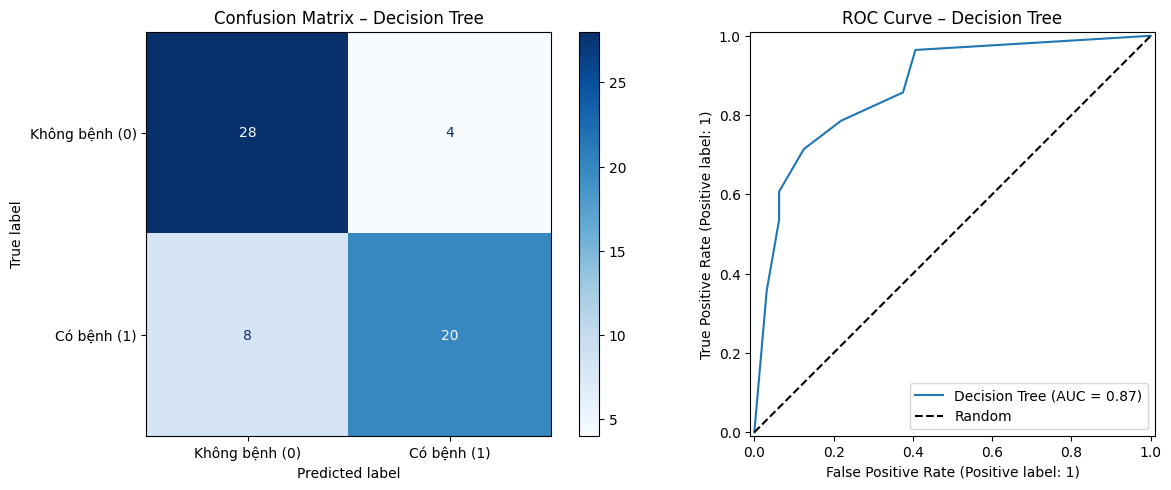

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Không bệnh (0)", "Có bệnh (1)"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Confusion Matrix – Decision Tree")

RocCurveDisplay.from_predictions(
    y_test, y_score,
    name="Decision Tree",
    ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], "k--", label="Random")
axes[1].set_title("ROC Curve – Decision Tree")
axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Vẽ cây quyết định

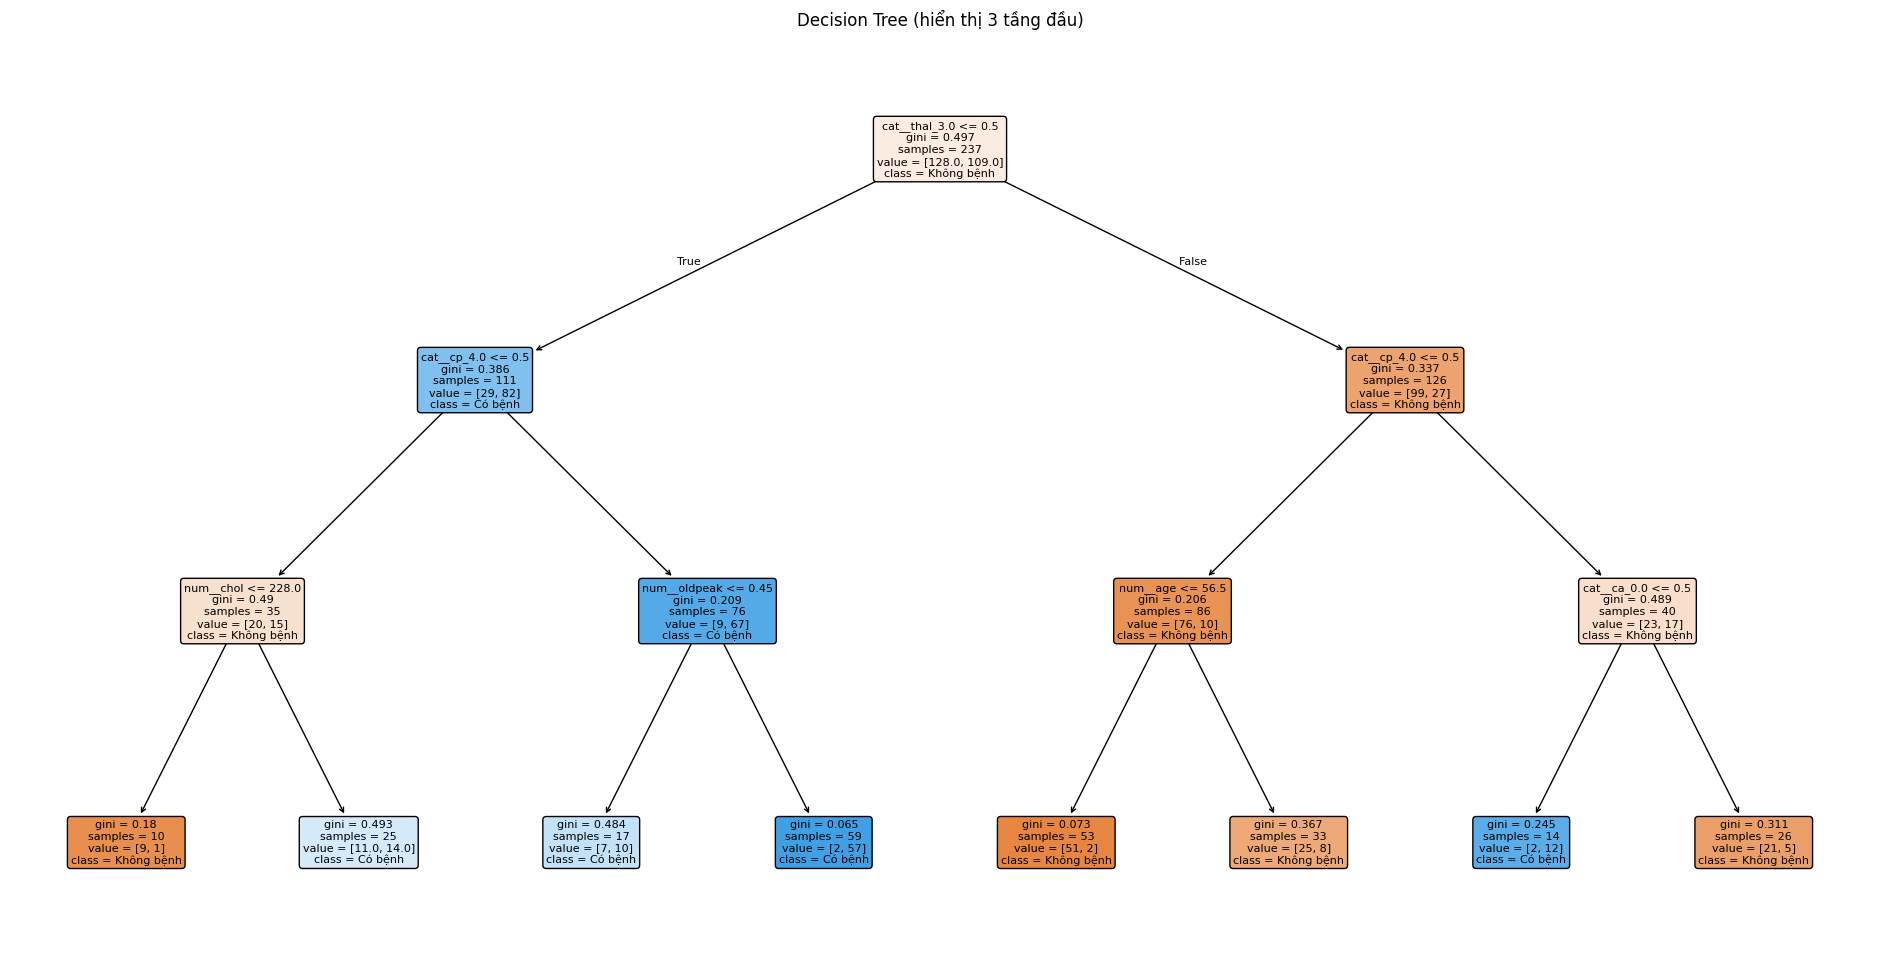

In [9]:
# Chỉ hiển thị tối đa 3 tầng để hình dễ đọc.
# Đây là hình minh họa; mô hình đánh giá vẫn dùng cây với tham số tối ưu.
fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_tree = best_model.named_steps["model"]
transformed_names = fitted_preprocessor.get_feature_names_out()

plt.figure(figsize=(24, 12))
plot_tree(
    fitted_tree,
    feature_names=transformed_names,
    class_names=["Không bệnh", "Có bệnh"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Decision Tree (hiển thị 3 tầng đầu)")
plt.show()

## 9. Phân tích Feature Importance

,Feature,Importance
25,cat__thal_3.0,0.506894
10,cat__cp_4.0,0.234838
21,cat__ca_0.0,0.125611
4,num__oldpeak,0.058847
2,num__chol,0.047200
0,num__age,0.026609
3,num__thalach,0.000000
1,num__trestbps,0.000000
7,cat__cp_1.0,0.000000
8,cat__cp_2.0,0.000000


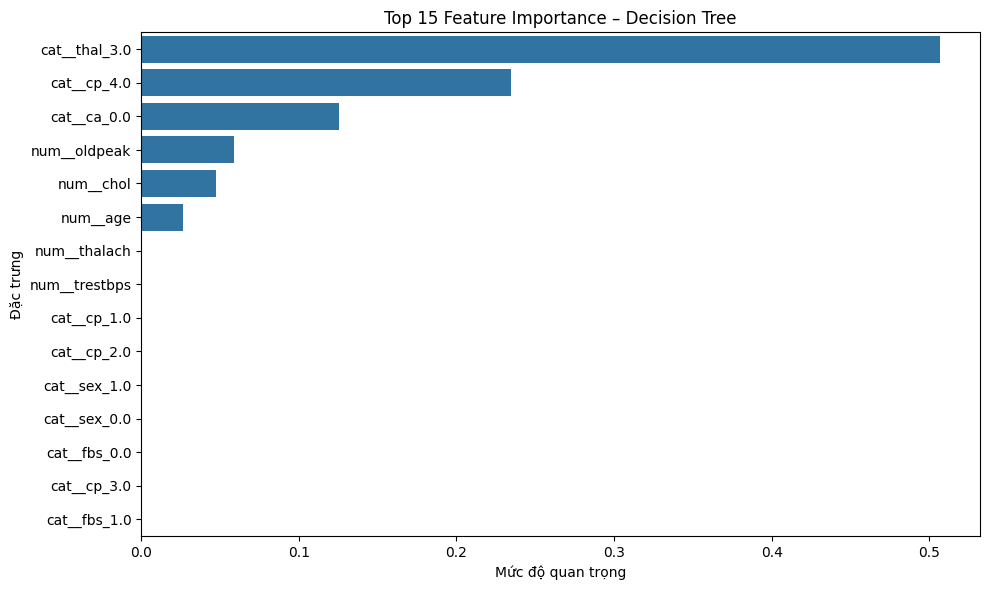

In [10]:
importance_df = pd.DataFrame({
    "Feature": transformed_names,
    "Importance": fitted_tree.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Top 15 Feature Importance – Decision Tree")
plt.xlabel("Mức độ quan trọng")
plt.ylabel("Đặc trưng")
plt.tight_layout()
plt.show()

## 10. Đánh giá Overfitting

In [11]:
# So sánh ROC-AUC trên phần train và validation qua 5 fold
print(f"Train ROC-AUC trung bình      : {train_auc_mean:.4f}")
print(f"Validation ROC-AUC trung bình : {val_auc_mean:.4f}")
gap = train_auc_mean - val_auc_mean
print(f"Độ chênh lệch                  : {gap:.4f}")

if gap > 0.10:
    print("Nhận xét: Có dấu hiệu overfitting tương đối rõ.")
elif gap > 0.05:
    print("Nhận xét: Có chênh lệch train-validation; cần theo dõi overfitting.")
else:
    print("Nhận xét: Chênh lệch nhỏ, chưa thấy dấu hiệu overfitting rõ rệt.")

print("\\nĐối chiếu thêm max_depth và min_samples_leaf:")
print(grid_search.best_params_)

Train ROC-AUC trung bình      : 0.9132
Validation ROC-AUC trung bình : 0.8384
Độ chênh lệch                  : 0.0747
Nhận xét: Có chênh lệch train-validation; cần theo dõi overfitting.
\nĐối chiếu thêm max_depth và min_samples_leaf:
{'model__max_depth': 3, 'model__min_samples_leaf': 10}


## 11. Xuất dictionary và kết quả cho TV5

In [12]:
result = {
    "Model": "Decision Tree",
    "Accuracy_mean": float(cv_results["test_accuracy"].mean()),
    "Accuracy_std": float(cv_results["test_accuracy"].std()),
    "Precision_mean": float(cv_results["test_precision"].mean()),
    "Recall_mean": float(cv_results["test_recall"].mean()),
    "F1_mean": float(cv_results["test_f1"].mean()),
    "ROC_AUC_mean": float(cv_results["test_roc_auc"].mean()),
    "Best_params": {
        "max_depth": best_model.named_steps["model"].max_depth,
        "min_samples_leaf": best_model.named_steps["model"].min_samples_leaf
    },
    "Note": "Decision Tree; tuning theo ROC-AUC bằng Stratified 5-Fold CV."
}

print(json.dumps(result, indent=4, ensure_ascii=False))

# Lưu đúng các file để gửi TV5
with open("TV1_DecisionTree_result.json", "w", encoding="utf-8") as f:
    json.dump(result, f, indent=4, ensure_ascii=False)

np.save("TV1_y_pred.npy", y_pred)
np.save("TV1_y_score.npy", y_score)

print("\\nĐã lưu: TV1_DecisionTree_result.json, TV1_y_pred.npy, TV1_y_score.npy")

{
    "Model": "Decision Tree",
    "Accuracy_mean": 0.7804078014184397,
    "Accuracy_std": 0.09885670058799406,
    "Precision_mean": 0.7934814814814815,
    "Recall_mean": 0.741991341991342,
    "F1_mean": 0.757729856910602,
    "ROC_AUC_mean": 0.8384239094239094,
    "Best_params": {
        "max_depth": 3,
        "min_samples_leaf": 10
    },
    "Note": "Decision Tree; tuning theo ROC-AUC bằng Stratified 5-Fold CV."
}
\nĐã lưu: TV1_DecisionTree_result.json, TV1_y_pred.npy, TV1_y_score.npy
